# The surface code, decoded by every decoder we have

Our surface code results so far used one decoder, PyMatching (minimum-weight perfect matching), the standard choice and
essentially optimal for the surface code. The gross code needs different decoders (BP-OSD, Relay-BP, ...), because its faults do
not form a graph. This notebook asks the reverse question: **how do the qLDPC decoders do on the surface code?** Do they match
PyMatching, and where do they fall short?

| Decoder | Package | Idea in one line |
|---|---|---|
| MWPM | PyMatching | pair up the fired detectors along the cheapest paths |
| Union-Find | stabilizer-qec | grow clusters around fired detectors until each can be explained, then peel |
| BP only | ldpc | belief propagation, 80 iterations, no second step |
| BP-OSD | ldpc | BP, then linear algebra over the most likely faults (order 10) |
| BP-LSD | ldpc | BP, then the same linear algebra on small local clusters (order 10) |
| Relay-BP | IBM relay_bp | BP repeated in a chain with memory and random weights |
| Ambiguity Clustering | stabilizer-qec | BP, then independent clusters, deciding each one's logical effect |

How each works, with the maths: `decoders_explained.md` in this folder. The full sweep is `run_sweep.py` (its results are in
`results_surface_decoders.csv`); this notebook runs a small version live and then plots the full results.

Run time: under a minute, plus a one-off clone of IBM's repository (for the circuits).

In [ ]:
%pip install -q stim sinter pymatching==2.4.0 ldpc==2.4.1 beliefmatching stabilizer-qec numpy pandas matplotlib
# Optional (IBM's own Relay-BP; needs Rust on Windows). Without it, stabilizer-qec's Relay-BP is used:
# %pip install -q "relay-bp[stim]"

In [2]:
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import stim

sys.path.insert(0, "../helpers")
import common              # ../helpers/common.py: IBM circuits, Wilson intervals
import decoders as D       # decoders.py: one wrapper per decoder, same interface

## 1. The problem every decoder gets

IBM's rotated surface code circuits (uniform circuit noise, $d$ rounds), keeping only the Z-check detectors, as IBM does.
Stim turns each circuit into a detector error model: every possible fault, its probability, the detectors it flips and whether
it flips the logical qubit.

Matching needs every fault to flip at most two detectors (an edge in a graph). For the surface code Stim can split every fault
into such pieces. For the gross code it cannot: most faults flip 3 to 6 detectors at once (a hypergraph). That is the
structural reason PyMatching works on one and not the other:

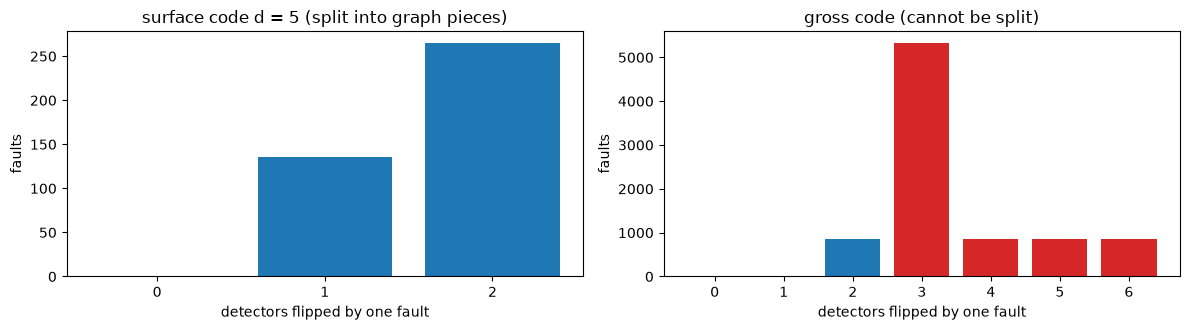

In [3]:
def detectors_per_fault(dem):
    counts = []
    for e in dem.flattened():
        if e.type == "error":
            for part in str(e).split(" ^ "):                     # pieces of a decomposed fault
                counts.append(sum(1 for t in part.split() if t.startswith("D")))
    return np.bincount(counts)

surface5 = common.ibm_circuit("rotated_surface_code_memory_Z", 5, 0.003, z_detectors_only=True)
gross = common.ibm_circuit("bicycle_bivariate_144_12_12_memory_Z", 12, 0.003, z_detectors_only=True)
surf_counts = detectors_per_fault(surface5.detector_error_model(decompose_errors=True))
gross_counts = detectors_per_fault(gross.detector_error_model(decompose_errors=False))

fig, axs = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, counts, title in [(axs[0], surf_counts, "surface code d = 5 (split into graph pieces)"),
                          (axs[1], gross_counts, "gross code (cannot be split)")]:
    ax.bar(range(len(counts)), counts, color=["tab:blue" if k <= 2 else "tab:red" for k in range(len(counts))])
    ax.set_xlabel("detectors flipped by one fault"); ax.set_ylabel("faults"); ax.set_title(title)
    ax.set_xticks(range(len(counts)))
plt.tight_layout(); plt.show()

Blue: faults that are edges (≤ 2 detectors). Red: hyperedges. The surface code is all blue, so matching applies. The gross
code has most of its faults flipping 3 to 6 detectors.

The BP-based decoders don't need edges: they work on the matrix $H$ (detectors × faults) directly, so they run on both.

## 2. A small live run

$d$ = 3 and 5 at $p = 0.004$, 5,000 shots sampled once per distance and given to every decoder.

In [4]:
rows = []
for d in (3, 5):
    circuit = common.ibm_circuit("rotated_surface_code_memory_Z", d, 0.004, z_detectors_only=True)
    dem = circuit.detector_error_model(decompose_errors=True)
    dets, obs = circuit.compile_detector_sampler(seed=d).sample(5000, separate_observables=True)
    for cls in D.ALL:
        t = time.time()
        pred = np.asarray(cls(dem).predict(dets)).reshape(len(dets), -1).astype(bool)
        rows.append((d, cls.name, int((pred != obs).any(axis=1).sum()), round(time.time() - t, 2)))
live = pd.DataFrame(rows, columns=["d", "decoder", "failures", "seconds"])
live.pivot(index="decoder", columns="d", values="failures").loc[[c.name for c in D.ALL]].rename(columns=lambda d: f"failures, d = {d}")

d,"failures, d = 3","failures, d = 5"
decoder,,
MWPM (PyMatching),72,45
Union-Find,75,50
BP only,206,309
BP-OSD,75,46
BP-LSD,80,56
Relay-BP,66,44
Ambiguity Clustering,72,44


Out of 5,000 shots. Everything except plain BP lands close to matching. Plain BP fails several times more often, and more at
$d = 5$ than at $d = 3$.

## 3. The full sweep

`run_sweep.py`: $d$ = 3, 5, 7, 9; $p$ = 0.002 to 0.008; 20,000 shots per point, the same shots for every decoder.

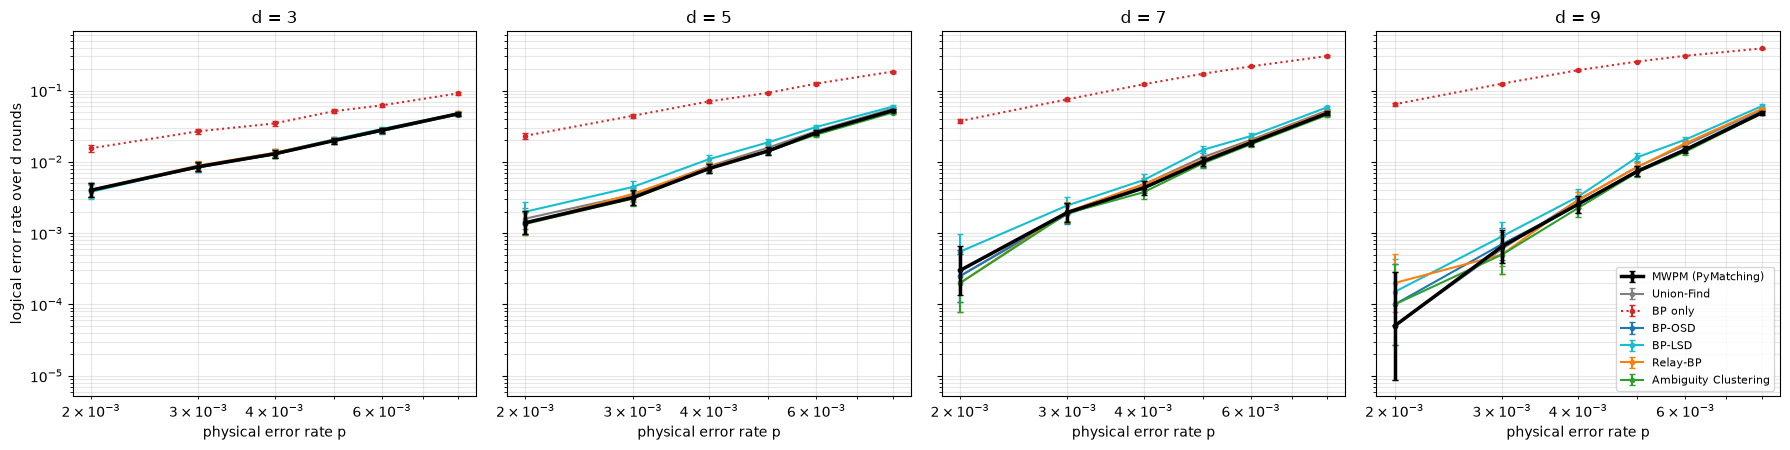

In [5]:
r = pd.read_csv("results_surface_decoders.csv")
r["P_L"] = r.failures / r.shots
r[["lo", "hi"]] = [common.wilson(f, n) for f, n in zip(r.failures, r.shots)]
ORDER = [c.name for c in D.ALL]
STYLE = {"MWPM (PyMatching)": dict(color="black", lw=2.5, zorder=5), "Union-Find": dict(color="tab:gray"),
         "BP only": dict(color="tab:red", ls=":"), "BP-OSD": dict(color="tab:blue"), "BP-LSD": dict(color="tab:cyan"),
         "Relay-BP": dict(color="tab:orange"), "Ambiguity Clustering": dict(color="tab:green")}

fig, axs = plt.subplots(1, 4, figsize=(18, 4.6), sharey=True)
for ax, (d, rd) in zip(axs, r.groupby("d")):
    for name in ORDER:
        x = rd[(rd.decoder == name) & (rd.failures > 0)].sort_values("p")
        ax.errorbar(x.p, x.P_L, yerr=[x.P_L - x.lo, x.hi - x.P_L], marker="o", ms=3, capsize=2, label=name, **STYLE[name])
    ax.set_xscale("log"); ax.set_yscale("log"); ax.grid(which="both", alpha=0.3)
    ax.set_title(f"d = {d}"); ax.set_xlabel("physical error rate p")
axs[0].set_ylabel("logical error rate over d rounds")
axs[-1].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

All decoders except plain BP sit almost on top of matching. To see the differences, divide each decoder's error rate by
matching's at the same point (above 1 = worse than matching):

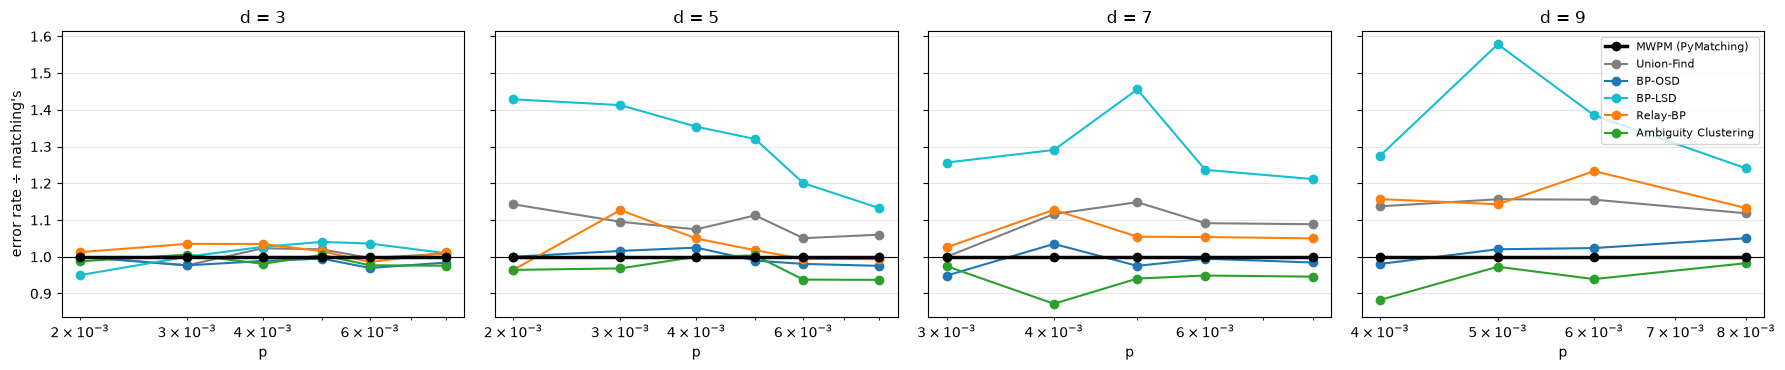

d,"mean ratio, d = 3","mean ratio, d = 5","mean ratio, d = 7","mean ratio, d = 9"
decoder,,,,
MWPM (PyMatching),1.00,1.00,1.00,1.00
Union-Find,1.00,1.09,1.09,1.14
BP-OSD,0.99,1.00,0.99,1.02
BP-LSD,1.01,1.31,1.29,1.37
Relay-BP,1.02,1.02,1.06,1.17
Ambiguity Clustering,0.99,0.97,0.94,0.94


In [6]:
mw = r[r.decoder == "MWPM (PyMatching)"].set_index(["d", "p"]).P_L
r["vs MWPM"] = r.apply(lambda row: row.P_L / mw[(row.d, row.p)], axis=1)
ok = r[(r.failures >= 20) & (r.decoder != "BP only")]           # points with enough failures to compare

fig, axs = plt.subplots(1, 4, figsize=(18, 3.8), sharey=True)
for ax, (d, rd) in zip(axs, ok.groupby("d")):
    for name in ORDER:
        x = rd[rd.decoder == name].sort_values("p")
        if len(x): ax.plot(x.p, x["vs MWPM"], marker="o", label=name, **STYLE[name])
    ax.axhline(1, color="k", lw=0.8); ax.set_xscale("log"); ax.set_title(f"d = {d}"); ax.set_xlabel("p"); ax.grid(alpha=0.3)
axs[0].set_ylabel("error rate ÷ matching's")
axs[-1].legend(fontsize=8)
plt.tight_layout(); plt.show()

(ok.pivot_table(index="decoder", columns="d", values="vs MWPM", aggfunc="mean").loc[[n for n in ORDER if n != "BP only"]]
   .round(2).rename(columns=lambda d: f"mean ratio, d = {d}"))

### Plain BP

Plain BP is in a class of its own, and the reason is the point of every BP-based decoder:

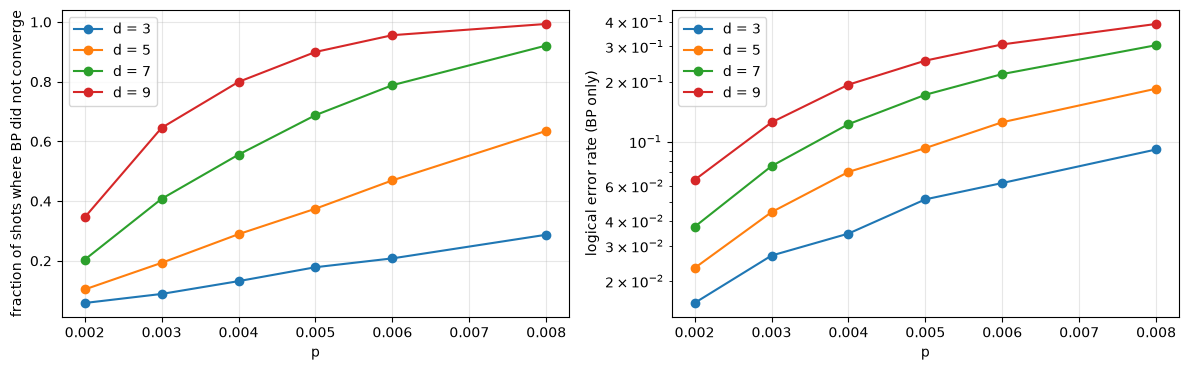

In [7]:
bp = r[r.decoder == "BP only"].copy()
bp["did not converge"] = bp.bp_not_converged / bp.shots
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8))
for d, x in bp.groupby("d"):
    a1.plot(x.p, x["did not converge"], marker="o", label=f"d = {d}")
    a2.plot(x.p, x.P_L, marker="o", label=f"d = {d}")
a1.set_ylabel("fraction of shots where BP did not converge"); a2.set_ylabel("logical error rate (BP only)")
a2.set_yscale("log")
for a in (a1, a2): a.set_xlabel("p"); a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()

As $d$ grows, BP fails to converge on more and more shots (most of them at $d = 9$), and its error rate goes **up** with
distance: plain BP has no threshold on the surface code. The surface code is full of short cycles and of equally good
explanations of the same syndrome (degeneracy), which is exactly what stops BP from settling. Every other BP decoder here is BP
plus a step that takes over when BP does not converge.

### Time

Seconds per 1,000 shots on a 2-core machine, all decoders given the same shots:

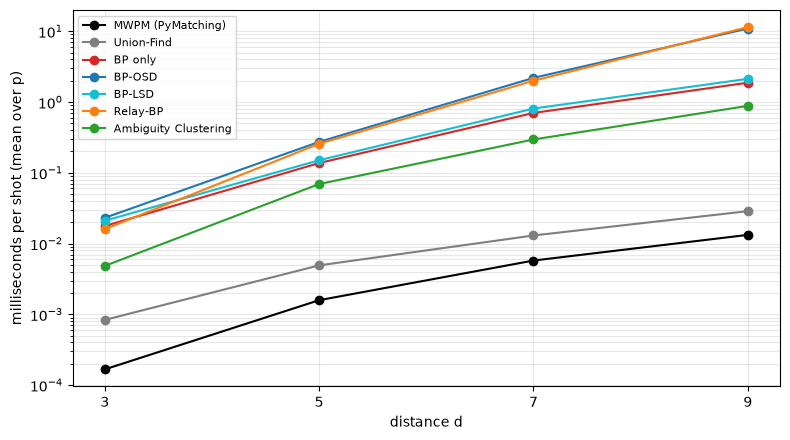

d,3,5,7,9
decoder,,,,
MWPM (PyMatching),0.000,0.002,0.006,0.013
Union-Find,0.001,0.005,0.013,0.029
BP only,0.018,0.137,0.700,1.873
BP-OSD,0.023,0.273,2.192,10.912
BP-LSD,0.021,0.150,0.808,2.125
Relay-BP,0.016,0.257,1.995,11.429
Ambiguity Clustering,0.005,0.069,0.295,0.882


In [8]:
r["ms per shot"] = 1000 * r.seconds / r.shots
t = r.groupby(["decoder", "d"])["ms per shot"].mean().unstack().loc[ORDER]
ax = t.T.plot(marker="o", figsize=(8, 4.5), logy=True, style={n: "-" for n in ORDER},
              color=[STYLE[n]["color"] for n in ORDER])
ax.set_xlabel("distance d"); ax.set_ylabel("milliseconds per shot (mean over p)"); ax.grid(which="both", alpha=0.3)
ax.set_xticks(t.columns); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
t.round(3)

## 5. Why BP-OSD ties with matching, and why Ambiguity Clustering wins

A **minimum-weight** decoder picks the single most likely fault set $\hat e$ and reports its logical effect. A **class**
decoder picks the logical outcome with the most total probability, adding up every fault set that gives it. They disagree
only when the two logical classes are nearly tied. For each shot, the **gap**

$$g = w(\text{best fault set in the other class}) - w(\text{best fault set}) = \ln \frac{P(\hat e)}{P(\hat e_{\text{other}})}$$

measures how close the tie is. Matching and BP-OSD are both minimum-weight decoders; Ambiguity Clustering adds a local class
decision inside its clusters. `investigate_ac.py` decoded the same 20,000 shots per point with variants that change one thing
at a time (full write-up: `decoders_explained.md`, section 11).

In [9]:
ai = pd.read_csv("results_ac_investigation.csv")
z = np.load("ac_investigation_shots.npz")
V = list(z["variants"])
display(ai.pivot_table(index="variant", columns=["d", "p"], values="failures").loc[V])

def paired(a, b):
    """McNemar: shots where only a fails, only b fails, and z = (b_only - c_only) / sqrt(sum)."""
    only_a = only_b = 0
    for k in [k for k in z.files if k.endswith("_fails")]:
        f = z[k]
        only_a += int((f[V.index(a)] & ~f[V.index(b)]).sum()); only_b += int((~f[V.index(a)] & f[V.index(b)]).sum())
    return only_a, only_b, round((only_a - only_b) / np.sqrt(only_a + only_b), 1)

pairs = [("MWPM", "MWPM exact"), ("MWPM exact", "BP-OSD-CS10"), ("MWPM exact", "AC kappa=0"),
         ("MWPM exact", "AC kappa=0.05"), ("AC kappa=0", "AC kappa=0.05")]
pd.DataFrame([(a, b, *paired(a, b)) for a, b in pairs],
             columns=["first", "second", "only first fails", "only second fails", "z"])

d                  5             7            9       
p              0.004  0.006  0.004  0.006 0.004  0.006
variant                                               
MWPM           161.0  514.0   86.0  372.0  51.0  296.0
MWPM exact     162.0  505.0   86.0  369.0  47.0  289.0
BP-OSD-0       169.0  561.0  103.0  421.0  66.0  381.0
BP-OSD-CS10    165.0  504.0   89.0  370.0  50.0  303.0
AC kappa=0     155.0  521.0   89.0  379.0  56.0  320.0
AC kappa=0.05  161.0  482.0   75.0  353.0  45.0  278.0
AC kappa=0.2   161.0  486.0   76.0  353.0  45.0  281.0

,first,second,only first fails,only second fails,z
0,MWPM,MWPM exact,115,93,1.5
1,MWPM exact,BP-OSD-CS10,30,53,-2.5
2,MWPM exact,AC kappa=0,167,229,-3.1
3,MWPM exact,AC kappa=0.05,192,128,3.6
4,AC kappa=0,AC kappa=0.05,266,140,6.3


All 120,000 shots. $|z| > 2$ means a real difference.

- *MWPM vs MWPM exact*: matching on Stim's graph vs matching on the exact fault table. No real difference.
- *MWPM exact vs BP-OSD-CS10*: BP-OSD fails slightly more often, on a handful of shots. On a graph, matching finds the
  minimum-weight fault set exactly; BP-OSD searches for the same thing approximately. So it can at best tie, and it does.
- *AC with $\kappa = 0$* (BP + OSD-0, no clusters) is worse than matching; the default AC is better. The gain comes from the
  cluster step.

Which shots does AC win? The gap, for random shots and for the shots where matching and AC disagree:

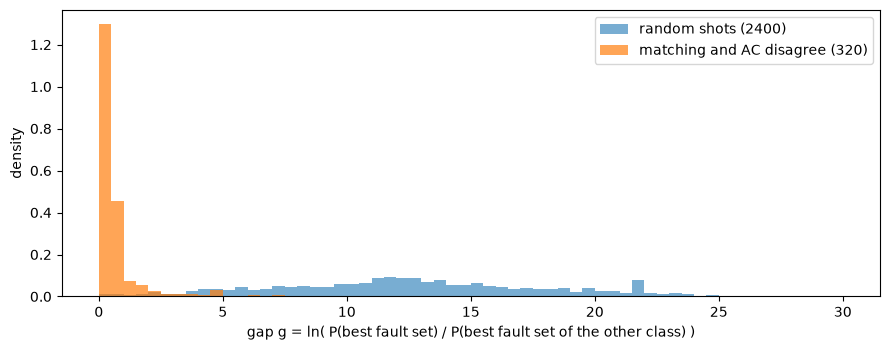

median gap: random 12.4, disagreements 0.29;  disagreements with g < 1: 281 of 320


In [10]:
rand_g, dis_g = [], []
for k in [k[:-6] for k in z.files if k.endswith("_fails")]:
    f, idx, g = z[k + "_fails"], z[k + "_gap_idx"], z[k + "_gap"]
    mw, ac = f[V.index("MWPM exact")][idx], f[V.index("AC kappa=0.05")][idx]
    sample = np.isin(idx, np.random.default_rng(int(k[1])).choice(20_000, 400, replace=False))
    rand_g += list(g[sample]); dis_g += list(g[mw != ac])

bins = np.linspace(0, 30, 61)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(rand_g, bins, alpha=0.6, density=True, label=f"random shots ({len(rand_g)})")
ax.hist(dis_g, bins, alpha=0.7, density=True, label=f"matching and AC disagree ({len(dis_g)})")
ax.set_xlabel("gap g = ln( P(best fault set) / P(best fault set of the other class) )"); ax.set_ylabel("density")
ax.legend(); plt.tight_layout(); plt.show()
print("median gap: random %.1f, disagreements %.2f;  disagreements with g < 1: %d of %d"
      % (np.median(rand_g), np.median(dis_g), sum(np.array(dis_g) < 1), len(dis_g)))

Matching and AC disagree almost only on near-ties: shots whose best fault sets in the two classes differ in probability
by a factor of about 1.1 to 1.5. There, picking the single best fault set is close to a coin flip; AC compares how much
probability each class has nearby, and wins more of these contests than it loses. That is the ~6% at $d$ = 7–9. AC's class
decision is local, so it is still not the optimal decoder.

## 6. What this shows

Results from `run_sweep.py`: $d$ = 3, 5, 7, 9; $p$ = 0.002 to 0.008; 20,000 shots per point, the same shots for every decoder.
Mean of (decoder's error rate ÷ matching's) over the points with at least 20 failures:

| Decoder | d = 3 | d = 5 | d = 7 | d = 9 | ms per shot at d = 9 |
|---|---|---|---|---|---|
| MWPM (PyMatching) | 1.00 | 1.00 | 1.00 | 1.00 | 0.013 |
| Union-Find | 1.00 | 1.09 | 1.09 | 1.14 | 0.029 |
| BP only | 2.7 | 9.1 | 38 | 270 | 1.9 |
| BP-OSD | 0.99 | 1.00 | 0.99 | 1.02 | 10.9 |
| BP-LSD | 1.01 | 1.31 | 1.29 | 1.37 | 2.1 |
| Relay-BP | 1.02 | 1.02 | 1.06 | 1.17 | 11.4 |
| Ambiguity Clustering | 0.99 | 0.97 | 0.94 | 0.94 | 0.88 |

1. **Plain BP has no threshold on the surface code.** It does not converge on 6–29% of shots at $d = 3$ and 35–99% at $d = 9$,
   and its error rate rises with distance (at $p = 0.004$: 3.5% at $d = 3$, 19% at $d = 9$). Short cycles and degeneracy
   (`decoders_explained.md`, section 4) are the cause. Every working BP decoder is BP plus a step for the shots where BP fails.
2. **BP-OSD equals matching** within the statistical error at every distance, and is about 800 times slower at $d = 9$
   (section 5 explains why).
3. **Ambiguity Clustering is slightly better than matching** at larger $d$ (about 6% fewer failures at $d$ = 7 and 9; e.g.
   $d = 9$, $p = 0.006$: 1.39% vs 1.48%), and the fastest of the BP-based decoders. Single points are within error of each
   other; the advantage is the consistency across points. Section 5 tests why: AC
   makes a (local) class decision on near-tied shots, where matching only picks the single most likely fault set.
4. **Union-Find** is 9–14% worse than matching at $d \ge 5$, as expected for an almost-linear-time approximation to it.
5. **BP-LSD** is 30–40% worse than matching at $d \ge 5$ with order 10. Its clusters are built from BP's soft output, which is
   poor when BP does not converge, which on the surface code is most shots at large $d$. We did not tune it.
6. **Relay-BP** (IBM's defaults for the surface code) is close to matching but falls behind as $d$ grows (17% worse at $d = 9$)
   and is the slowest here. Its parameters were tuned by IBM for the gross code, not for these runs.

For the surface code, matching remains the right choice: as accurate as anything else here and 100–1000 times faster. The
BP-based decoders are built for codes where matching is not possible, such as the gross code.

## References

- IBM's surface code circuits: github.com/trmue/relay (Apache-2.0).
- O. Higgott and C. Gidney, *Sparse Blossom*, arXiv:2303.15933 (PyMatching).
- N. Delfosse and N. H. Nickerson, *Almost-linear time decoding algorithm for topological codes*, arXiv:1709.06218 (Union-Find).
- J. Roffe et al., *Decoding across the quantum LDPC code landscape*, arXiv:2005.07016 (BP, BP-OSD, `ldpc`).
- T. Hillmann et al., *Localized statistics decoding*, arXiv:2406.18655 (BP-LSD).
- T. Müller et al., *Improved belief propagation is sufficient for real-time decoding of quantum memory*, arXiv:2506.01779 (Relay-BP).
- S. Wolanski and B. Barber, *Ambiguity Clustering*, arXiv:2406.14527.
- Q. McNemar, Psychometrika 12, 153 (1947) (paired test).